# 2.28 · KL divergence: how different are two beliefs?

**Before this:** [2.03](2-03_probability_distributions.ipynb) (distributions), [2.27](2-27_entropy_information.ipynb) (entropy)  
**You will be able to:** compute and read a KL divergence; say which direction a fitting method minimises and what
that does to the reported uncertainty; explain why maximum likelihood picks the KL-closest model even when it is wrong  
**Optional sections:** 6 (non-Gaussianity), 7 (AIC preview; 2.29 does it properly)

2.27 measured how uncertain *one* distribution is. Very often we need to compare *two*: a posterior with the prior
(how much did we learn?), a curved posterior with the Gaussian a method reported (how much did the approximation
lose?), a noise model with the real errors (how wrong is our likelihood?). The Kullback-Leibler divergence
(Kullback & Leibler 1951) is the standard number for all three. It behaves like a distance in some ways and not in
others, and the "not" part matters in practice.

**Words this notebook defines:** KL divergence (relative entropy), cross-entropy, Gibbs' inequality, asymmetry,
mode-seeking and mass-covering fits, moment matching, variational inference, expected information gain, mutual
information, maximum likelihood, misspecified model, AIC (preview).

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| two Gaussians (sections 1-2) | 1 | none | none | none |
| a two-peak posterior (section 3) | 1 | none | target density only | no data |
| one slip value seen by one datum (section 4) | 1 | 1 | $d = G\,s$ + noise | linear |
| heavy-tailed errors fitted with a Gaussian (section 5) | 1 (the noise scale σ) | 10 to 100,000 values | none | none |
| one-station knob of notebook 2.25 (section 6) | 2 | 1 distance | distance to one station | nonlinear |
| polynomial fits (section 7) | 1 to 9 coefficients + noise variance | 30 | polynomial in $x$ | linear in the coefficients |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize, minimize_scalar
from scipy.stats import norm, t as tdist

import bayeskit as bk
from bayeskit import problems as P, diagnostics as D, plotting as BP, style as S

rng = np.random.default_rng(5)
C4 = [S.BLUE, S.ORANGE, S.AQUA, S.VIOLET]
LOG2E = 1 / np.log(2)


def kl_grid(p, q, dx):
    """D_KL(p || q) in nats for densities sampled on a grid with spacing dx."""
    ok = p > 1e-300
    return float(np.sum(p[ok] * (np.log(p[ok]) - np.log(np.maximum(q[ok], 1e-300)))) * dx)


def kl_gauss(m1, s1, m2, s2):
    """Closed form D_KL( N(m1, s1^2) || N(m2, s2^2) ) in nats."""
    return np.log(s2 / s1) + (s1 ** 2 + (m1 - m2) ** 2) / (2 * s2 ** 2) - 0.5

## 1. The definition, as a picture

**In plain words.** Suppose the world behaves like distribution $p$, but you plan with distribution $q$. Every
observation surprises you a little more than it would have if you had used $p$ (the *surprise* of an outcome is
$-\ln$ of the probability you gave it: none for a certain outcome, a lot for one you thought rare). The KL divergence
$D_{KL}(p\,\|\,q)$ is that extra surprise, averaged over what actually happens. In the language of 2.27 it is the number of extra
yes/no questions per observation you waste by using a questioning scheme designed for $q$ when the outcomes come
from $p$.

**Precisely.**

$$D_{KL}(p\,\|\,q) = \int p(x)\,\ln\frac{p(x)}{q(x)}\,dx = \underbrace{-\int p\ln q}_{\text{cross-entropy}} - \underbrace{\Big(-\int p \ln p\Big)}_{\text{entropy } H(p)} .$$

The cross-entropy is the average surprise when the outcomes come from $p$ but you score them with $q$; the entropy
$H(p)$ (2.27) is the unavoidable part. In nats with $\ln$, in bits with $\log_2$. The average is taken under $p$, the
distribution that generates the outcomes. Swapping the roles gives a different number.

saved figures/2-28_definition.png


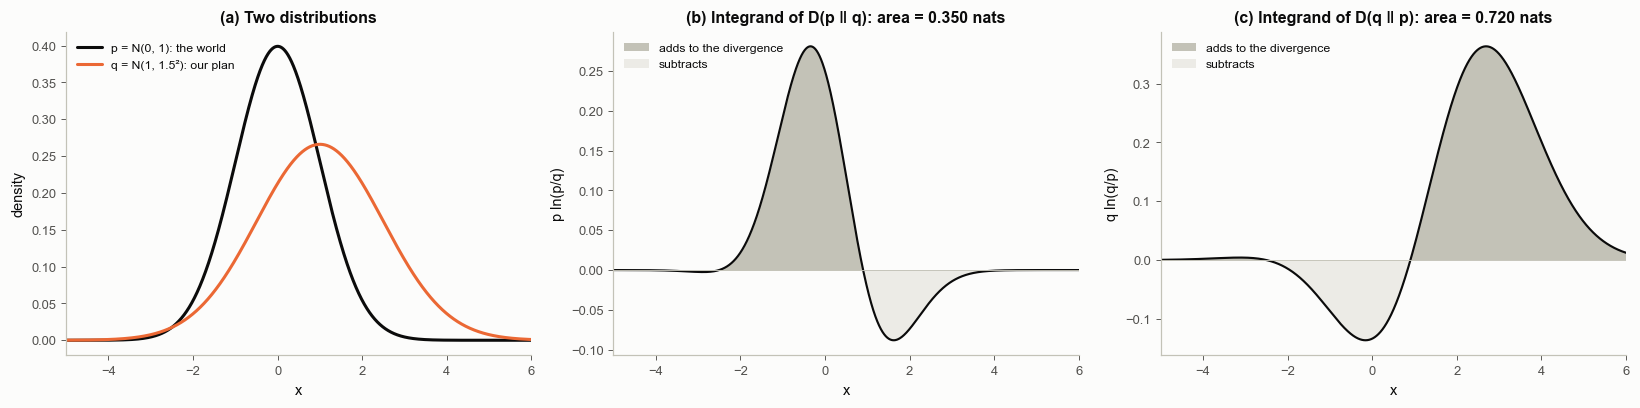

In [2]:
x = np.linspace(-7, 9, 6001)
dx = x[1] - x[0]
p_ = norm.pdf(x, 0, 1)
q_ = norm.pdf(x, 1, 1.5)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
ax = axs[0]
ax.plot(x, p_, color=S.INK, lw=2, label="p = N(0, 1): the world")
ax.plot(x, q_, color=S.ORANGE, lw=2, label="q = N(1, 1.5²): our plan")
ax.set_xlim(-5, 6); ax.set_xlabel("x"); ax.set_ylabel("density")
ax.set_title("(a) Two distributions")
ax.legend(fontsize=8, loc="upper left")
for ax, (a, b, name, nm) in zip(axs[1:], [(p_, q_, "D(p ‖ q)", "p ln(p/q)"), (q_, p_, "D(q ‖ p)", "q ln(q/p)")]):
    integrand = a * np.log(a / b)
    ax.fill_between(x, integrand, 0, where=integrand > 0, color="#c3c2b7", lw=0, label="adds to the divergence")
    ax.fill_between(x, integrand, 0, where=integrand < 0, color="#ecebe6", lw=0, label="subtracts")
    ax.plot(x, integrand, color=S.INK, lw=1.4)
    ax.axhline(0, color=S.AXIS, lw=0.6)
    ax.set_xlim(-5, 6); ax.set_xlabel("x"); ax.set_ylabel(nm)
    ax.set_title(f"({'b' if name == 'D(p ‖ q)' else 'c'}) Integrand of {name}: area = {kl_grid(a, b, dx):.3f} nats")
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-28_definition")
plt.show()

**How to read it.** (b) The dark area minus the light area is $D(p\,\|\,q)$: where the world puts probability but
$q$ does not expect it, the integrand is large. (c) The same with the roles swapped gives a different area. Both
areas are positive.

**Worked example.** For two Gaussians the integral has a closed form:
$D\big(N(\mu_1,\sigma_1^2)\,\|\,N(\mu_2,\sigma_2^2)\big) = \ln\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1-\mu_2)^2}{2\sigma_2^2} - \frac12$.
Each term for the pair above, then the numerical integral as a check:

In [3]:
for lab, (m1, s1, m2, s2), (a, b) in [("D(p || q)", (0, 1, 1, 1.5), (p_, q_)), ("D(q || p)", (1, 1.5, 0, 1), (q_, p_))]:
    t1, t2 = np.log(s2 / s1), (s1 ** 2 + (m1 - m2) ** 2) / (2 * s2 ** 2)
    print(f"{lab}: ln(s2/s1) = {t1:+.4f}, (s1^2 + (m1-m2)^2) / (2 s2^2) = {t2:.4f}, minus 1/2"
          f"  ->  {t1 + t2 - 0.5:.4f} nats = {(t1 + t2 - 0.5) * LOG2E:.4f} bits   (numerical integral {kl_grid(a, b, dx):.4f})")

D(p || q): ln(s2/s1) = +0.4055, (s1^2 + (m1-m2)^2) / (2 s2^2) = 0.4444, minus 1/2  ->  0.3499 nats = 0.5048 bits   (numerical integral 0.3499)
D(q || p): ln(s2/s1) = -0.4055, (s1^2 + (m1-m2)^2) / (2 s2^2) = 1.6250, minus 1/2  ->  0.7195 nats = 1.0381 bits   (numerical integral 0.7195)


**Common misreadings.**
* "KL is a distance." It is not symmetric and it does not obey the triangle inequality (for a true distance a detour
  is never shorter: $d(a,c) \le d(a,b) + d(b,c)$); the order of the arguments
  is part of the question you are asking.
* "A small KL means the curves look alike everywhere." KL weighs disagreements by $p$; a mismatch in a region where
  $p$ is tiny costs almost nothing.

## 2. Never negative, and zero only when the two agree

**In plain words.** You can never gain, on average, by planning with the wrong distribution: the extra surprise is
zero when $q = p$ and positive otherwise. That is what makes KL usable as a measure of mismatch.

**Precisely.** Gibbs' inequality: $D_{KL}(p\,\|\,q) \ge 0$, with equality only if $p = q$ almost everywhere (except on a set of zero probability). Proof in
one line with Jensen's inequality: for a function that curves downward (concave), such as the logarithm, the function
of an average is at least the average of the function, $\ln E[X] \ge E[\ln X]$ (2.32 uses the same inequality for
derived quantities). Here:
$-D_{KL} = \int p\ln\frac{q}{p} \le \ln\int p\,\frac{q}{p} = \ln 1 = 0$.

saved figures/2-28_never_negative.png


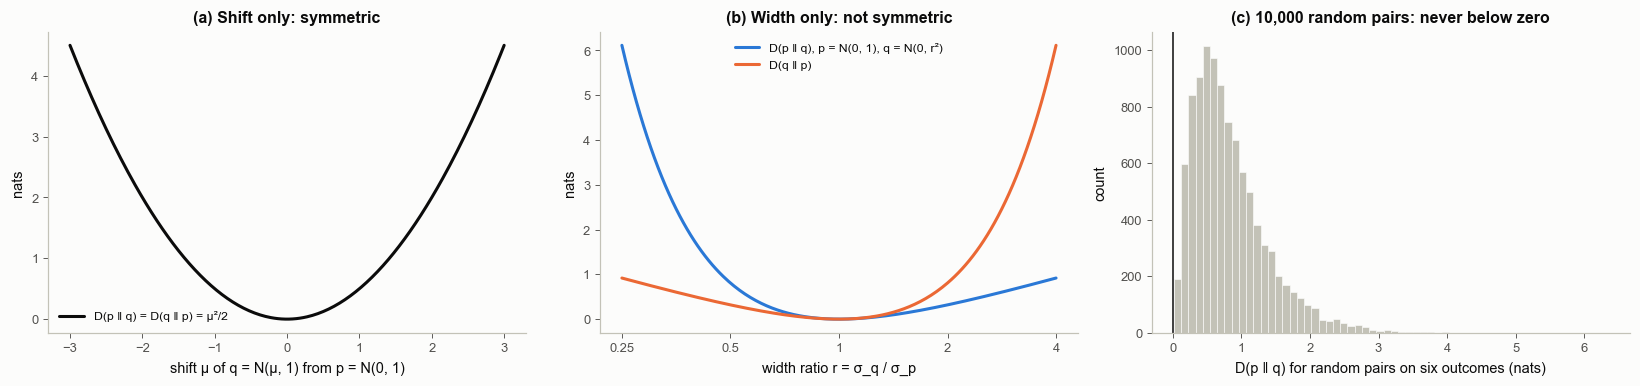

smallest of 10,000 random discrete divergences: 0.01375 nats (none negative: True)
width example: q twice as wide as p: D(p||q) = 0.3181, D(q||p) = 0.8069 nats


In [4]:
mus = np.linspace(-3, 3, 241)
ratios = np.geomspace(0.25, 4, 241)
pairs = []
for _ in range(10000):
    a = rng.dirichlet(np.ones(6)); b = rng.dirichlet(np.ones(6))
    pairs.append(np.sum(a * np.log(a / b)))
pairs = np.array(pairs)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
ax = axs[0]
ax.plot(mus, kl_gauss(0, 1, mus, 1), color=S.INK, lw=2, label="D(p ‖ q) = D(q ‖ p) = μ²/2")
ax.set_xlabel("shift μ of q = N(μ, 1) from p = N(0, 1)"); ax.set_ylabel("nats")
ax.set_title("(a) Shift only: symmetric"); ax.legend(fontsize=8)
ax = axs[1]
ax.semilogx(ratios, kl_gauss(0, 1, 0, ratios), color=C4[0], lw=2, label="D(p ‖ q), p = N(0, 1), q = N(0, r²)")
ax.semilogx(ratios, kl_gauss(0, ratios, 0, 1), color=C4[1], lw=2, label="D(q ‖ p)")
ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4"]); ax.minorticks_off()
ax.set_xlabel("width ratio r = σ_q / σ_p"); ax.set_ylabel("nats")
ax.set_title("(b) Width only: not symmetric"); ax.legend(fontsize=8, loc="upper center")
ax = axs[2]
ax.hist(pairs, bins=60, color="#c3c2b7", edgecolor=S.SURFACE, lw=0.4)
ax.axvline(0, color=S.INK, lw=1)
ax.set_xlabel("D(p ‖ q) for random pairs on six outcomes (nats)"); ax.set_ylabel("count")
ax.set_title("(c) 10,000 random pairs: never below zero")
fig.tight_layout()
bk.savefig(fig, "2-28_never_negative")
plt.show()
print(f"smallest of 10,000 random discrete divergences: {pairs.min():.5f} nats (none negative: {bool(np.all(pairs >= 0))})")
print(f"width example: q twice as wide as p: D(p||q) = {kl_gauss(0, 1, 0, 2):.4f}, D(q||p) = {kl_gauss(0, 2, 0, 1):.4f} nats")

**How to read it.** (a) Moving $q$ sideways costs the same in both directions. (b) Making $q$ too *narrow* is
punished much harder by $D(p\,\|\,q)$ than making it too wide: if $p$ produces outcomes where $q$ says "almost
impossible", the surprise is enormous. The other direction punishes the opposite mistake. (c) Every random pair gives
a positive number.

**Common misreadings.**
* "Zero KL can happen for different distributions." Only if they differ on a set of zero probability.

## 3. The asymmetry matters: one Gaussian for a two-peak posterior

**In plain words.** Suppose the true posterior $p$ has two peaks (the two-station location problem of notebook 2.02 is
like this) and a method must summarise it by one Gaussian $q$. "Best" depends on which divergence you minimise.
Minimising $D(q\,\|\,p)$ forbids $q$ from putting probability where $p$ has none, so $q$ hides inside one peak and is
too narrow (*mode-seeking*). Minimising $D(p\,\|\,q)$ forbids $q$ from missing anywhere $p$ has probability, so $q$
stretches over both peaks and puts probability in the empty valley (*mass-covering*); the solution is the Gaussian
with the same mean and variance as $p$ (*moment matching*).

**Precisely.** Over Gaussians $q = N(\mu, s^2)$: $\arg\min D(p\,\|\,q)$ has $\mu = E_p[x]$, $s^2 = \mathrm{Var}_p[x]$.
$\arg\min D(q\,\|\,p)$ has no closed form and can have several local minima. Variational inference (VI) minimises
$D(q\,\|\,p)$ over a chosen family of simple distributions (reminder: 2.21), which is one reason VI often under-states uncertainty (often, not always: a counterexample is computed at
the end of this section). Methods that report one Gaussian for a nonlinear
problem (Laplace, EKF, EnKI) are not defined as minimisers of either divergence; notebooks 2.24 and 2.25 show where
their Gaussians land.

In [5]:
xx = np.linspace(-8, 8, 4001)
dxx = xx[1] - xx[0]
p2 = 0.6 * norm.pdf(xx, -2, 0.6) + 0.4 * norm.pdf(xx, 2, 0.6)
mean_p = np.sum(xx * p2) * dxx
sd_p = np.sqrt(np.sum((xx - mean_p) ** 2 * p2) * dxx)
rev = lambda th: kl_grid(norm.pdf(xx, th[0], np.exp(th[1])), p2, dxx)
fwd = lambda th: kl_grid(p2, norm.pdf(xx, th[0], np.exp(th[1])), dxx)
fits_rev = {}
for start in (-2.5, 0.0, 2.5):
    r = minimize(rev, [start, 0.0], method="Nelder-Mead", options=dict(xatol=1e-9, fatol=1e-12, maxiter=5000))
    fits_rev[start] = (r.x[0], np.exp(r.x[1]), r.fun)
r = minimize(fwd, [0.0, 0.0], method="Nelder-Mead", options=dict(xatol=1e-9, fatol=1e-12, maxiter=5000))
fit_fwd = (r.x[0], np.exp(r.x[1]), r.fun)
# Laplace approximation at the highest peak (MAP), from the curvature of ln p
imap = int(np.argmax(p2))
lp = np.log(p2)
curv = (lp[imap + 1] - 2 * lp[imap] + lp[imap - 1]) / dxx ** 2
lap = (xx[imap], 1 / np.sqrt(-curv))
print(f"true posterior p: mean {mean_p:+.3f}, sd {sd_p:.3f}; probability in the valley |x| < 0.8: {np.sum(p2[np.abs(xx) < 0.8]) * dxx:.4f}")
for start, (m_, s_, v_) in fits_rev.items():
    print(f"minimise D(q||p) from start {start:+.1f}: mu {m_:+.3f}, sd {s_:.3f}, D = {v_:.4f} nats")
print(f"minimise D(p||q):               mu {fit_fwd[0]:+.3f}, sd {fit_fwd[1]:.3f}, D = {fit_fwd[2]:.4f} nats  (moments of p: {mean_p:+.3f}, {sd_p:.3f})")
qf = norm.pdf(xx, fit_fwd[0], fit_fwd[1])
print(f"probability the moment-matched q puts in the valley |x| < 0.8: {np.sum(qf[np.abs(xx) < 0.8]) * dxx:.3f}")
print(f"Laplace approximation at the MAP: mu {lap[0]:+.3f}, sd {lap[1]:.3f}")

mgrid = np.linspace(-3.5, 3.5, 141)
prof_rev, prof_fwd = [], []
for m_ in mgrid:
    prof_rev.append(minimize_scalar(lambda ls: rev([m_, ls]), bounds=(np.log(0.1), np.log(5)), method="bounded").fun)
    prof_fwd.append(minimize_scalar(lambda ls: fwd([m_, ls]), bounds=(np.log(0.1), np.log(8)), method="bounded").fun)

true posterior p: mean -0.400, sd 2.049; probability in the valley |x| < 0.8: 0.0228
minimise D(q||p) from start -2.5: mu -1.998, sd 0.604, D = 0.5098 nats
minimise D(q||p) from start +0.0: mu -0.313, sd 1.764, D = 1.1432 nats
minimise D(q||p) from start +2.5: mu +1.996, sd 0.606, D = 0.9146 nats
minimise D(p||q):               mu -0.400, sd 2.049, D = 0.5566 nats  (moments of p: -0.400, 2.049)
probability the moment-matched q puts in the valley |x| < 0.8: 0.298
Laplace approximation at the MAP: mu -2.000, sd 0.600


saved figures/2-28_asymmetry.png


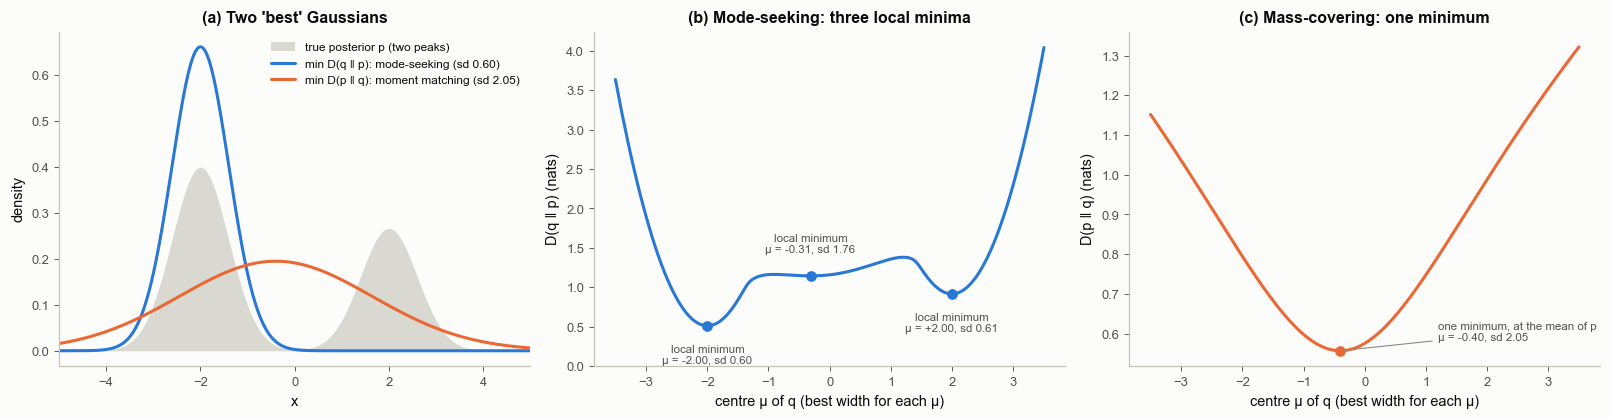

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
ax = axs[0]
ax.fill_between(xx, p2, color="#d9d8d1", lw=0, label="true posterior p (two peaks)")
g_rev = fits_rev[-2.5]
ax.plot(xx, norm.pdf(xx, g_rev[0], g_rev[1]), color=C4[0], lw=2, label=f"min D(q ‖ p): mode-seeking (sd {g_rev[1]:.2f})")
ax.plot(xx, qf, color=C4[1], lw=2, label=f"min D(p ‖ q): moment matching (sd {fit_fwd[1]:.2f})")
ax.set_xlim(-5, 5); ax.set_xlabel("x"); ax.set_ylabel("density")
ax.set_title("(a) Two 'best' Gaussians"); ax.legend(fontsize=7.8, loc="upper right")
ax = axs[1]
ax.plot(mgrid, prof_rev, color=C4[0], lw=2)
for start, (m_, s_, v_) in fits_rev.items():
    ax.plot(m_, v_, "o", color=C4[0], ms=6)
    below = abs(m_) > 1                                        # the two peak minima: label underneath the curve
    ax.annotate(f"local minimum\nμ = {m_:+.2f}, sd {s_:.2f}", (m_, v_), textcoords="offset points",
                xytext=(0, -12 if below else 14), ha="center", va="top" if below else "bottom", fontsize=7.5, color=S.INK2)
ax.set_xlabel("centre μ of q (best width for each μ)"); ax.set_ylabel("D(q ‖ p) (nats)")
ax.set_title("(b) Mode-seeking: three local minima"); ax.set_ylim(0, max(prof_rev) * 1.05)
ax = axs[2]
ax.plot(mgrid, prof_fwd, color=C4[1], lw=2)
ax.plot(fit_fwd[0], fit_fwd[2], "o", color=C4[1], ms=6)
ax.annotate(f"one minimum, at the mean of p\nμ = {fit_fwd[0]:+.2f}, sd {fit_fwd[1]:.2f}", (fit_fwd[0], fit_fwd[2]),
            xytext=(1.2, fit_fwd[2] + 0.02), textcoords="data", ha="left", va="bottom", fontsize=7.5, color=S.INK2,
            arrowprops=dict(arrowstyle="-", color=S.MUTED, lw=0.7))
ax.set_xlabel("centre μ of q (best width for each μ)"); ax.set_ylabel("D(p ‖ q) (nats)")
ax.set_title("(c) Mass-covering: one minimum")
fig.tight_layout()
bk.savefig(fig, "2-28_asymmetry")
plt.show()

**How to read it.** (a) The mode-seeking Gaussian sits on the bigger peak and ignores the other; the moment-matched
Gaussian covers both, and puts a sizeable share of its probability in the valley where the true posterior has almost
none (printed above). (b) $D(q\,\|\,p)$ has a local minimum at each peak and a broad one between them: an optimiser
finds whichever is nearest its start. The Laplace approximation (2.08: a Gaussian centred at the MAP whose width comes
from the curvature of $\ln p$ there), built from the curvature at the highest peak, lands
almost exactly on the mode-seeking fit here. (c) $D(p\,\|\,q)$ has a single minimum, at the mean of $p$.

**Common misreadings.**
* "Variational inference gives the posterior uncertainty." It gives the uncertainty of the $q$ that minimises
  $D(q\,\|\,p)$ within the chosen family (and of whichever local minimum the optimiser stops at). That $q$ is often
  narrower than the posterior, as here, but "reverse KL is always narrower" is not a theorem: the next cell finds a
  unimodal posterior whose best reverse-KL Gaussian is *wider* than it. What VI reports depends on the family, the
  shape of the posterior and the optimisation (notebook 2.21 tests several families).
* "The moment-matched Gaussian is safe." It has the right mean and variance, but in a two-peak case its most likely
  value is where the posterior has almost no probability.

In [7]:
# counterexample: p = 1/2 N(0, 0.01^2) + 1/2 N(0, 1) (a sharp spike on a broad base, one peak); best Gaussian q = N(0, s^2)
xs_ = np.linspace(-12, 12, 400001)
dxs = xs_[1] - xs_[0]
p_sp = 0.5 * norm.pdf(xs_, 0, 0.01) + 0.5 * norm.pdf(xs_, 0, 1.0)
sd_p = np.sqrt(np.sum(p_sp * xs_ ** 2) * dxs)
log_s = np.linspace(np.log(0.003), np.log(3.0), 300)
rkl = []
for ls in log_s:
    q_ = norm.pdf(xs_, 0, np.exp(ls))
    ok = q_ > 1e-300
    rkl.append(np.sum(q_[ok] * (np.log(q_[ok]) - np.log(p_sp[ok]))) * dxs)
rkl = np.array(rkl)
loc = [k for k in range(1, len(rkl) - 1) if rkl[k] < rkl[k - 1] and rkl[k] < rkl[k + 1]]
print(f"posterior sd = {sd_p:.3f}")
for k in loc:
    print(f"local minimum of D(q||p): q sd = {np.exp(log_s[k]):.3f}, D = {rkl[k]:.3f} nats" + ("   <- global" if rkl[k] == rkl.min() else ""))

posterior sd = 0.707
local minimum of D(q||p): q sd = 0.010, D = 0.665 nats
local minimum of D(q||p): q sd = 0.967, D = 0.613 nats   <- global


## 4. From prior to posterior: KL is the information the datum delivered

**In plain words.** Comparing the posterior with the prior measures how much one particular datum changed our mind:
both by narrowing the distribution and by moving it. A datum that lands where we expected moves little; a surprising
datum moves more. Averaged over all the data we might have received, this is exactly the information gain of 2.27.

**Precisely.** For one slip value with prior $N(0,\sigma_m^2)$ and datum $d = Gs + e$, $e\sim N(0,\sigma_d^2)$, the
posterior is $N(\bar s, \tilde\sigma^2)$ with $\tilde\sigma^2 = (1/\sigma_m^2 + G^2/\sigma_d^2)^{-1}$ and
$\bar s = \tilde\sigma^2 G d/\sigma_d^2$. Then $D(\text{posterior}\,\|\,\text{prior})$ depends on $d$ (through $\bar s$),
and its average over the prior predictive distribution of $d$ (the data the experiment could produce when the slip is
drawn from the prior; 2.11) is the mutual information
$\tfrac12\ln(1 + G^2\sigma_m^2/\sigma_d^2)$ (in nats; 2.27 gave it in bits).

**Worked example.** $\sigma_m = 1$ m, $G = 1$ (unit sensitivity, so $d$ is in metres too), $\sigma_d = 0.5$ m,
observed $d = 1.2$ m.

In [8]:
sm, G1, sd_ = 1.0, 1.0, 0.5
d_obs = 1.2
v_post = 1 / (1 / sm ** 2 + G1 ** 2 / sd_ ** 2)
m_post = v_post * G1 * d_obs / sd_ ** 2
print(f"posterior variance = 1 / (1/{sm}^2 + {G1}^2/{sd_}^2) = {v_post:.4f}  ->  sd {np.sqrt(v_post):.4f}")
print(f"posterior mean     = {v_post:.4f} x {G1} x {d_obs} / {sd_}^2 = {m_post:.4f}")
kl_pp = kl_gauss(m_post, np.sqrt(v_post), 0, sm)
print(f"D(posterior || prior) = ln(sd_prior/sd_post) + (var_post + mean_post^2)/(2 var_prior) - 1/2 = {kl_pp:.4f} nats = {kl_pp * LOG2E:.4f} bits")
mi = 0.5 * np.log(1 + G1 ** 2 * sm ** 2 / sd_ ** 2)
print(f"mutual information 1/2 ln(1 + G^2 sm^2 / sd^2) = {mi:.4f} nats = {mi * LOG2E:.4f} bits (the average over all possible data)")
mt = sm * rng.standard_normal(200000)                        # Monte Carlo: draw a slip from the prior, then a datum
dd = G1 * mt + sd_ * rng.standard_normal(mt.size)
kls = kl_gauss(v_post * G1 * dd / sd_ ** 2, np.sqrt(v_post), 0, sm)
print(f"Monte Carlo average of D(posterior || prior) over 200,000 simulated data: {kls.mean():.4f} ± {kls.std() / np.sqrt(kls.size):.4f} nats")

posterior variance = 1 / (1/1.0^2 + 1.0^2/0.5^2) = 0.2000  ->  sd 0.4472
posterior mean     = 0.2000 x 1.0 x 1.2 / 0.5^2 = 0.9600
D(posterior || prior) = ln(sd_prior/sd_post) + (var_post + mean_post^2)/(2 var_prior) - 1/2 = 0.8655 nats = 1.2487 bits
mutual information 1/2 ln(1 + G^2 sm^2 / sd^2) = 0.8047 nats = 1.1610 bits (the average over all possible data)
Monte Carlo average of D(posterior || prior) over 200,000 simulated data: 0.8044 ± 0.0013 nats


saved figures/2-28_information_gain.png


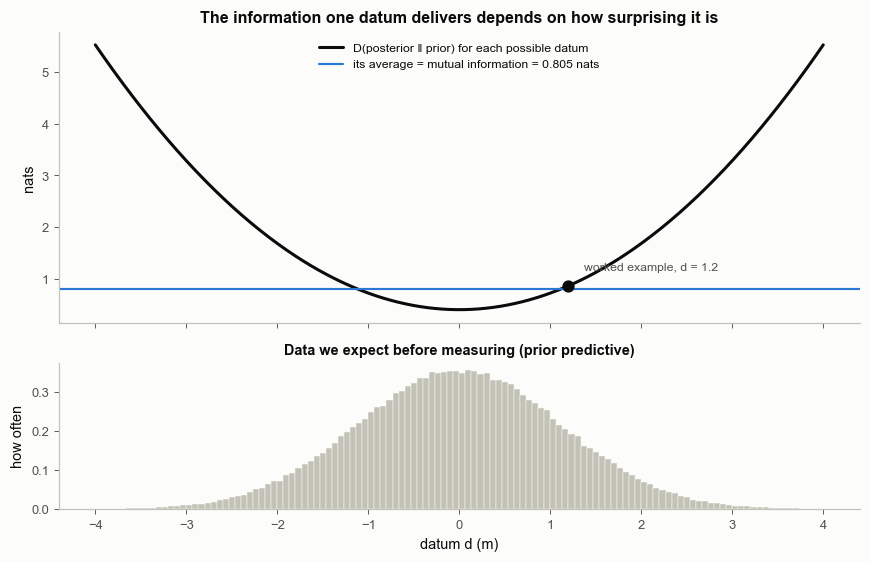

In [9]:
dgrid = np.linspace(-4, 4, 400)
fig, axs = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
ax = axs[0]
ax.plot(dgrid, kl_gauss(v_post * G1 * dgrid / sd_ ** 2, np.sqrt(v_post), 0, sm), color=S.INK, lw=2,
        label="D(posterior ‖ prior) for each possible datum")
ax.axhline(mi, color=C4[0], lw=1.4, label=f"its average = mutual information = {mi:.3f} nats")
ax.plot(d_obs, kl_pp, "o", color=S.INK, ms=7)
ax.annotate(f"worked example, d = {d_obs}", (d_obs, kl_pp), textcoords="offset points", xytext=(10, 10), fontsize=8, color=S.INK2)
ax.set_ylabel("nats"); ax.legend(fontsize=8, loc="upper center")
ax.set_title("The information one datum delivers depends on how surprising it is")
ax = axs[1]
ax.hist(dd, bins=120, range=(-4, 4), density=True, color="#c3c2b7", edgecolor=S.SURFACE, lw=0.3)
ax.set_xlabel("datum d (m)"); ax.set_ylabel("how often")
ax.set_title("Data we expect before measuring (prior predictive)", fontsize=9.5)
fig.tight_layout()
bk.savefig(fig, "2-28_information_gain")
plt.show()

**How to read it.** A datum near zero (what the prior expects) narrows the distribution without moving it, and
delivers the least; data far in the tails also move it, and deliver more. Weighted by how often each datum occurs
(bottom), the average is the mutual information, the same quantity as the information gain of 2.27. The Monte Carlo
check above confirms the equality to its sampling error.

## 5. Maximum likelihood is minimum KL (even when the model is wrong)

**In plain words.** Fitting a model by maximum likelihood chooses, among the distributions the model allows, the one
closest in KL to whatever really produced the data. If the model family is right, that is the truth. If it is wrong,
maximum likelihood still converges, to the *closest wrong answer*. A Gaussian noise model fitted to heavy-tailed
errors is the classic case: the fitted σ grows to absorb the outliers.

**Precisely.** With data $x_i$ drawn from $p$ and a model $q_\theta$,
$\frac1n\sum_i \ln q_\theta(x_i) \to E_p[\ln q_\theta] = -H(p) - D_{KL}(p\,\|\,q_\theta)$ by the Law of Large Numbers
(2.05), so the maximum-likelihood $\theta$ converges to $\arg\min_\theta D_{KL}(p\,\|\,q_\theta)$.

Experiment: errors from a Student-t distribution (2.03) with 4 degrees of freedom (scale 1: a normal-looking core with heavy
tails), modelled as Gaussian $N(0, \sigma^2)$.

In [10]:
nu = 4
pt = lambda u: tdist.pdf(u, nu)
klsig = lambda s: quad(lambda u: pt(u) * (tdist.logpdf(u, nu) - norm.logpdf(u, 0, s)), -np.inf, np.inf, limit=200)[0]
best = minimize_scalar(klsig, bounds=(0.5, 3.0), method="bounded", options=dict(xatol=1e-10))
var_t = quad(lambda u: u ** 2 * pt(u), -np.inf, np.inf)[0]
print(f"KL-closest Gaussian to the t({nu}) errors: sigma = {best.x:.4f};  sqrt(variance of t({nu})) = {np.sqrt(var_t):.4f};  D_KL there = {best.fun:.4f} nats")
print(f"for comparison, a Gaussian matching the core (sigma = 1): D_KL = {klsig(1.0):.4f} nats")
ns = [10, 100, 1000, 10000, 100000]
print(f"{'n':>7s} {'mean of 200 MLE sigmas':>23s} {'their spread (sd)':>18s}")
for n in ns:
    sig_hat = [np.sqrt(np.mean(rng.standard_t(nu, n) ** 2)) for _ in range(200)]
    print(f"{n:7d} {np.mean(sig_hat):23.4f} {np.std(sig_hat):18.4f}")

KL-closest Gaussian to the t(4) errors: sigma = 1.4142;  sqrt(variance of t(4)) = 1.4142;  D_KL there = 0.0838 nats
for comparison, a Gaussian matching the core (sigma = 1): D_KL = 0.2372 nats
      n  mean of 200 MLE sigmas  their spread (sd)
     10                  1.3474             0.5895


    100                  1.3843             0.1899
   1000                  1.4085             0.0759
  10000                  1.4175             0.0507


 100000                  1.4123             0.0086


saved figures/2-28_mle_is_min_kl.png


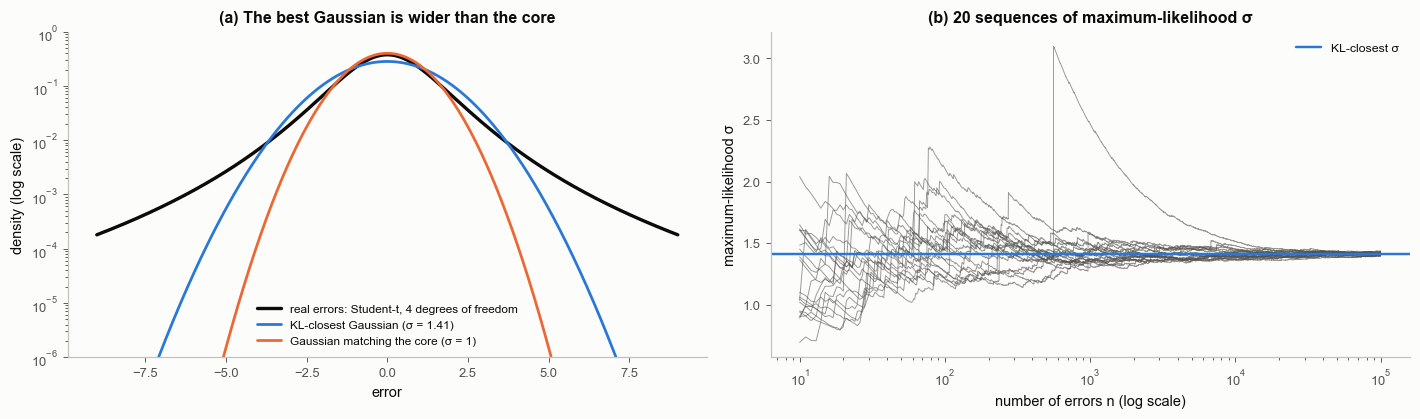

In [11]:
nmax = 100000
paths = []
for k in range(20):
    e = rng.standard_t(nu, nmax)
    paths.append(np.sqrt(np.cumsum(e ** 2) / np.arange(1, nmax + 1)))
paths = np.array(paths)
uu = np.linspace(-9, 9, 2001)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
ax = axs[0]
ax.semilogy(uu, pt(uu), color=S.INK, lw=2.2, label="real errors: Student-t, 4 degrees of freedom")
ax.semilogy(uu, norm.pdf(uu, 0, best.x), color=C4[0], lw=1.8, label=f"KL-closest Gaussian (σ = {best.x:.2f})")
ax.semilogy(uu, norm.pdf(uu, 0, 1.0), color=C4[1], lw=1.8, label="Gaussian matching the core (σ = 1)")
ax.set_ylim(1e-6, 1); ax.set_xlabel("error"); ax.set_ylabel("density (log scale)")
ax.set_title("(a) The best Gaussian is wider than the core"); ax.legend(fontsize=7.8, loc="lower center")
ax = axs[1]
nn = np.arange(1, nmax + 1)
for k in range(20):
    ax.semilogx(nn[9:], paths[k, 9:], color=S.INK2, lw=0.6, alpha=0.6)
ax.axhline(best.x, color=C4[0], lw=1.6, label="KL-closest σ")
ax.set_xlabel("number of errors n (log scale)"); ax.set_ylabel("maximum-likelihood σ")
ax.set_title("(b) 20 sequences of maximum-likelihood σ"); ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-28_mle_is_min_kl")
plt.show()

**How to read it.** (a) On a log scale the heavy tails of the real errors are obvious; the KL-closest Gaussian is
wider than the core so that the tails are not "impossible", and the Gaussian that matches the core has a larger
divergence (printed above). (b) Each grey line is one experiment in which errors keep arriving and σ is re-estimated
by maximum likelihood: they converge to the KL-closest value, slowly and with sudden jumps when a large error
arrives. That jumpiness is a heavy-tail effect: the variance of t(4) is finite but its fourth moment (the average of
$x^4$, which sets how much a variance estimate scatters) is not, so the
usual $1/\sqrt{n}$ behaviour of 2.05 does not apply to this estimate.

**Common misreadings.**
* "The fit converged, so the noise model is right." Maximum likelihood converges to the closest member of the family
  you chose, right or wrong.
* "A large fitted σ means uniformly noisy data." It can also mean a few large errors in otherwise precise data; plot
  the residuals.

## 6. KL as a measure of non-Gaussianity

**In plain words.** How far is a posterior from being Gaussian? Compare it with the Gaussian that has the same mean
and covariance. The KL divergence between them is zero for a Gaussian posterior and grows as the posterior curves,
splits or develops tails. It is also the least information any single Gaussian summary must lose.

**Precisely.** If $q$ is the Gaussian with the mean and covariance of $p$, then
$D_{KL}(p\,\|\,q) = H(q) - H(p)$: since $\ln q$ is quadratic, $-\int p\ln q = -\int q\ln q = H(q)$. Because the
Gaussian has the largest entropy for a given covariance (2.27), this is the *entropy deficit* of $p$. And because $q$
minimises $D(p\,\|\,\cdot)$ among all Gaussians (section 3), every other Gaussian summary diverges from $p$ at least
this much. Below: the one-station knob of notebook 2.25, where moving the station closer bends the posterior.

In [12]:
R_LIST = [30, 10, 5, 2.5, 1.5, 1.0, 0.6]
WIDE = (-4.5, 5.5, -5.0, 5.6)        # wider than the maps: no posterior probability may fall outside the grid
rows = []
grids = {}
for r_ in R_LIST:
    g = P.grid(P.location(kind="knob", r=r_), extent=WIDE, n=900)
    grids[r_] = g
    ok = g.P > 0
    Hp = -np.sum(g.P[ok] * np.log(g.P[ok])) * g.dx * g.dy
    Hq = 0.5 * np.log(np.linalg.det(2 * np.pi * np.e * g.cov))
    rows.append((r_, D.gaussianity(g)["kl"], Hq - Hp))
print(f"{'station distance r':>18s} {'D(p || Gaussian) (nats)':>24s} {'H(Gaussian) - H(p) (nats)':>26s}")
for r_, kl_, dh in rows:
    print(f"{r_:18g} {kl_:24.4f} {dh:26.4f}")

station distance r  D(p || Gaussian) (nats)  H(Gaussian) - H(p) (nats)
                30                   0.0262                     0.0262
                10                   0.1902                     0.1902
                 5                   0.4989                     0.4989
               2.5                   0.9517                     0.9517
               1.5                   1.2627                     1.2627
                 1                   1.1661                     1.1661
               0.6                   0.7548                     0.7548


saved figures/2-28_non_gaussianity.png


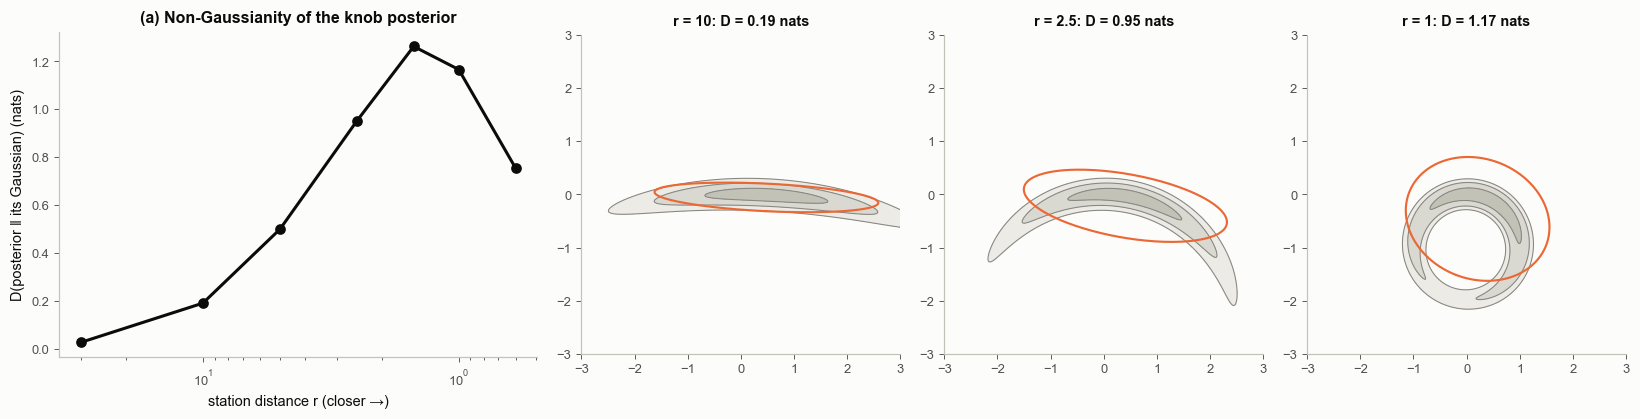

In [13]:
fig = plt.figure(figsize=(15, 3.9))
gs = fig.add_gridspec(1, 4, width_ratios=[1.5, 1, 1, 1])
ax = fig.add_subplot(gs[0])
ax.semilogx([r[0] for r in rows], [r[1] for r in rows], "o-", color=S.INK, lw=2)
ax.invert_xaxis()
ax.set_xlabel("station distance r (closer →)"); ax.set_ylabel("D(posterior ‖ its Gaussian) (nats)")
ax.set_title("(a) Non-Gaussianity of the knob posterior")
for k, r_ in enumerate([10, 2.5, 1.0]):
    a2 = fig.add_subplot(gs[k + 1])
    pr = P.location(kind="knob", r=r_)
    BP.density(a2, grids[r_])
    BP.ellipse(a2, grids[r_].mean, grids[r_].cov, nsig=np.sqrt(-2 * np.log(0.1)), color=C4[1], lw=1.4)
    BP.frame(a2, pr, equal=True, labels=False)
    a2.set_title(f"r = {r_:g}: D = {dict((rr, kk) for rr, kk, _ in rows)[r_]:.2f} nats", fontsize=9.5)
fig.tight_layout()
bk.savefig(fig, "2-28_non_gaussianity")
plt.show()

**How to read it.** (a) The divergence rises as the station moves closer and the posterior bends into a banana, and
falls again for the closest station, where the posterior becomes a fairly symmetric ring. (b-d) Grey: the exact
posterior; orange: the 90 % ellipse of the moment-matched Gaussian. The table confirms
$D(p\,\|\,q) = H(q) - H(p)$ to the printed precision. (The grid behind these numbers extends well beyond the maps
shown. On a window that cuts off part of the posterior, both numbers change and the identity fails by about the
probability lost at the edges, so check the window before trusting a gridded divergence.)

## 7. Preview: AIC estimates a KL divergence

**In plain words.** A model with more parameters always fits the data it was fitted to better. What we want is the
model that will predict *new* data best, that is, the one closest in KL to the process that makes the data. Akaike
(1974) showed that the training fit plus a penalty of two per parameter estimates that distance (up to a constant).
2.29 treats AIC, BIC and ABIC properly; here is the KL connection in one picture.

**Precisely.** $\mathrm{AIC} = -2\ln\hat L + 2k$ with $\hat L$ the maximised likelihood (the likelihood at the
maximum-likelihood parameters, 2.07) and $k$ the number of fitted
parameters. Its expectation approximates $-2\,E[\ln q_{\hat\theta}(\text{new data})] = 2\,[H(p) + D_{KL}(p\,\|\,q_{\hat\theta})]$.

Experiment: 30 noisy points of a smooth curve (noise σ = 0.3), polynomials of degree 0 to 8, averaged over 300 data
sets. The expected log-likelihood on fresh data at the same $x$ is computed exactly from the known truth.

 degree  -2 ln L (training)  -2 E ln L (new data)     AIC
      0                83.5                  84.3    87.5
      1                31.3                  35.4    37.3
      2                30.7                  36.1    38.7
      3                 7.6                  20.2    17.6
      4                 6.5                  22.0    18.5
      5                 4.9                  24.1    18.9
      6                 3.6                  26.7    19.6
      7                 2.3                  29.3    20.3
      8                 0.7                  32.5    20.7
best degree: by new-data fit 3, by AIC 3


saved figures/2-28_aic_preview.png


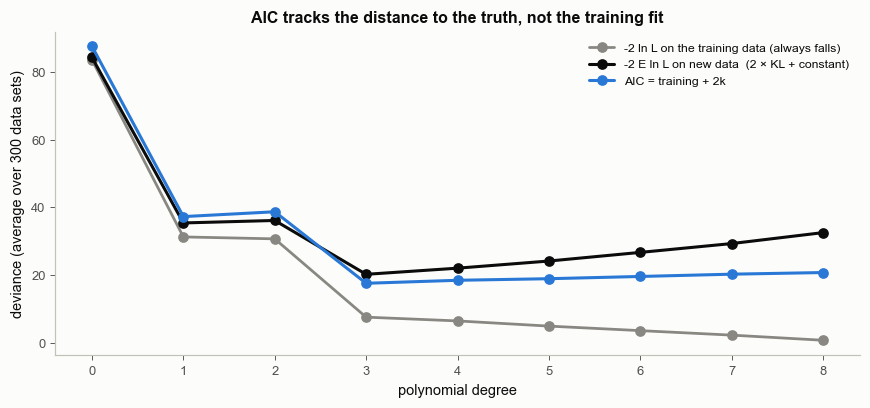

In [14]:
n_pts, s_true = 30, 0.3
xp = np.linspace(-1, 1, n_pts)
f_true = lambda u: np.sin(2.5 * u) + 0.3 * u
degs = np.arange(9)
R = 300
train, test, aic = np.zeros((R, 9)), np.zeros((R, 9)), np.zeros((R, 9))
for k in range(R):
    y = f_true(xp) + s_true * rng.standard_normal(n_pts)
    for dg in degs:
        V = np.vander(xp, dg + 1)
        c, *_ = np.linalg.lstsq(V, y, rcond=None)
        mu = V @ c
        s2 = np.mean((y - mu) ** 2)                                 # maximum-likelihood noise variance
        ll = -0.5 * n_pts * (np.log(2 * np.pi * s2) + 1)
        kpar = dg + 2                                               # coefficients + noise variance
        ell = np.sum(-0.5 * np.log(2 * np.pi * s2) - ((f_true(xp) - mu) ** 2 + s_true ** 2) / (2 * s2))
        train[k, dg], test[k, dg], aic[k, dg] = -2 * ll, -2 * ell, -2 * ll + 2 * kpar
print(f"{'degree':>7s} {'-2 ln L (training)':>19s} {'-2 E ln L (new data)':>21s} {'AIC':>7s}")
for dg in degs:
    print(f"{dg:7d} {train[:, dg].mean():19.1f} {test[:, dg].mean():21.1f} {aic[:, dg].mean():7.1f}")
print(f"best degree: by new-data fit {int(np.argmin(test.mean(0)))}, by AIC {int(np.argmin(aic.mean(0)))}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(degs, train.mean(0), "o-", color=S.MUTED, lw=1.8, label="-2 ln L on the training data (always falls)")
ax.plot(degs, test.mean(0), "o-", color=S.INK, lw=2, label="-2 E ln L on new data  (2 × KL + constant)")
ax.plot(degs, aic.mean(0), "o-", color=C4[0], lw=2, label="AIC = training + 2k")
ax.set_xlabel("polynomial degree"); ax.set_ylabel("deviance (average over 300 data sets)")
ax.set_title("AIC tracks the distance to the truth, not the training fit")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-28_aic_preview")
plt.show()

**How to read it.** The training deviance keeps falling as parameters are added. The deviance on new data, which is
twice the KL divergence from the truth plus a constant, has a minimum; AIC has its minimum at the same degree. At low
degree AIC is close to the new-data curve; as parameters are added it falls further and further below it: with many
parameters relative to 30 points the penalty of two per parameter is too small, and corrected versions exist. 2.29
continues from here.

## Summary

| use | divergence | what it tells you |
|---|---|---|
| posterior vs prior | $D(\text{post}\,\|\,\text{prior})$ | information delivered by this datum; its average is the mutual information (2.27) |
| approximation vs truth | $D(q\,\|\,p)$ (VI) or $D(p\,\|\,q)$ (moment matching) | mode-seeking vs mass-covering; choose deliberately |
| posterior vs its Gaussian | $D(p\,\|\,q_{\text{Gauss}}) = H(q) - H(p)$ | non-Gaussianity; the least loss of any Gaussian summary |
| data vs noise model | minimised by maximum likelihood | the closest member of your family, right or wrong |
| model vs future data | estimated by AIC | which model will predict best (2.29) |

**In practice.**
* When EnKI or an EKF summarises a curved posterior by one Gaussian, the knob numbers above are a lower bound on the
  information lost; notebook 2.25 measured the same curvature as a nonlinearity index.
* A per-data-set noise scale σ_k, estimated by maximum likelihood or sampled in a hierarchical model, settles on the
  KL-closest Gaussian. If the errors are heavy-tailed, σ_k grows to cover the outliers, and every datum of that set is
  down-weighted; plot the residuals to tell outliers from uniform noise.

Next: [**2.29 · Choosing hyperparameters and comparing models**](2-29_hyperparameters_information_criteria.ipynb).